# Evaluation of the rent models

Scores every model that has saved its predictions under `predictions/`, so models trained elsewhere take part by dropping their files there (the format is described in `evaluation_utils.py`). Each model is **fitted once, on the train months (2021-01..2024-03)**:

| folder | rows | what the predictions are |
|---|---|---|
| `predictions/val/<model>.csv` | the 35,158 validation rows (2024-04..2025-03) | **held out**: the model never saw these rents |
| `predictions/train/<model>.csv` | the 114,841 train rows (2021-01..2024-03) | **in-sample**: the model was fitted on these rows |
| `predictions/test/<model>.csv` | the 50,000 test rows (2025-03..2026-07), no rents | a forecast |
| `predictions/levels/<model>.csv` (optional) | the 67 months | the rent of a fixed set of flats (the flats of 2025-01..03) as predicted for each month, for the growth benchmark |

Each file holds `ROW_ID`, the identifier columns of the static features and `prediction`; the actual rents are read from `data/original_dataset/train.csv` by `ROW_ID`.
The test set has no rents, so the models are never refitted on the validation months: the validation rows are the only held-out rents the models can be compared on.

1. Held-out accuracy (MAE, RMSE, R2, bias in dollars) on the validation rows against month-only references, and by flat type and month.
2. In-sample accuracy on the train rows (the models were fitted on them).
3. Growth forecast for 2026 against the government growth band (the test set has no rents, so the forecast cannot be scored directly; it is also a longer extrapolation than the validation year).
4. Charts, and the training diagnostics of the neural networks (epoch losses, from their `results/tables/`).

Tables are saved under `tables/`, charts under `charts/`.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import evaluation_utils as eu

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
os.makedirs(eu.TABLE_DIR, exist_ok=True); os.makedirs(eu.CHART_DIR, exist_ok=True)
NN_TABLES = [eu.ROOT / '02_modelling' / kind / 'neural_network' / 'results' / 'tables' for kind in ('single_stage_models', 'two_stage_models')]      # training statistics of the neural networks
MODEL_STYLE = {'temporal_ffn': ('Temporal network only', eu.HUE['orange']),
               'static_temporal_ffn': ('Static + temporal network (single stage)', eu.HUE['aqua']),
               'two_stage_ffn_rf': ('Two-stage: FFN level x random forest', eu.HUE['violet']),
               'two_stage_lasso_rf': ('Two-stage: Lasso level x random forest', eu.HUE['magenta'])}        # other models: their file name and the next free colour

## 1. Load the predictions and the actual rents

In [2]:
models = eu.list_models()
actual = eu.load_actuals()
preds = {split: {m: eu.load_predictions(m, split) for m in models} for split in ('train', 'val', 'test')}

free = [c for c in eu.HUE_CYCLE if c not in {c for _, c in MODEL_STYLE.values()}]
style = {m: MODEL_STYLE.get(m) or (m, free.pop(0)) for m in models}
label = {m: s[0] for m, s in style.items()}

for split in ('train', 'val'):                                           # attach the actual rent by ROW_ID and check the rows line up
    for m, df in preds[split].items():
        a = actual.loc[df['ROW_ID']]
        assert (a['month'].to_numpy() == df['month'].to_numpy()).all(), (m, split)
        df['actual'], df['FLAT_TYPE'] = a[eu.LABEL].to_numpy(), a['FLAT_TYPE'].to_numpy()
for split in ('train', 'val', 'test'):
    ids = [df['ROW_ID'].to_numpy() for df in preds[split].values()]
    assert all((i == ids[0]).all() for i in ids), f'the models of {split} are not predicting the same rows'
    assert all(df['prediction'].notna().all() for df in preds[split].values())
val = preds['val'][models[0]]
train_rows = preds['train'][models[0]]
FIRST_VAL = int(val['month'].min())
assert train_rows['month'].max() == FIRST_VAL - 1, 'the train rows must end where the validation rows start'
print('models:', models)
print({s: len(next(iter(preds[s].values()))) for s in preds}, f'| train months 0..{FIRST_VAL - 1}, validation months {FIRST_VAL}..{int(val["month"].max())} ({eu.month_label(FIRST_VAL)[0]}..{eu.month_label(val["month"].max())[0]})')

fitted_rows = pd.concat([train_rows[['month', 'actual']], val[['month', 'actual']]])      # all the rows with a rent
month_mean = fitted_rows.groupby('month')['actual'].mean()                                   # actual level of each month 0..50

models: ['static_temporal_ffn', 'temporal_ffn', 'two_stage_ffn_rf', 'two_stage_lasso_rf']
{'train': 114841, 'val': 35158, 'test': 50000} | train months 0..38, validation months 39..50 (2024-04..2025-03)


## 2. Held-out accuracy (validation rows)

The month-only references use the months before the validation period (and the validation rents themselves for the first): the **monthly mean rent** is the best any model that sees only the month could do (a floor, it is not a forecast),
**carry-forward** repeats the mean rent of the last train month, and **straight-line trend** extends a linear fit of the monthly mean rent of the train months.

In [3]:
fit_months = np.arange(FIRST_VAL)
slope, intercept = np.polyfit(fit_months, month_mean.loc[fit_months], 1)
references = {'monthly mean rent (floor for month-only models)': month_mean.loc[val['month']].to_numpy(),
              f'carry-forward (mean rent of {eu.month_label(FIRST_VAL - 1)[0]})': np.full(len(val), month_mean.loc[FIRST_VAL - 1]),
              'straight-line trend of the monthly mean rent': intercept + slope * val['month'].to_numpy()}
held_out = pd.DataFrame({**{label[m]: eu.regression_metrics(preds['val'][m]['actual'], preds['val'][m]['prediction']) for m in models},
                         **{k: eu.regression_metrics(val['actual'], v) for k, v in references.items()}}).T
held_out.to_csv(eu.TABLE_DIR / 'validation_metrics.csv', index_label='model')
print(f'validation rows ({len(val):,}):'); print(held_out.round(3).to_string())

validation rows (35,158):
                                                     MAE     RMSE     R2     BIAS
Static + temporal network (single stage)         383.837  502.544  0.419  -96.569
Temporal network only                            507.508  664.364 -0.016  -75.642
Two-stage: FFN level x random forest             355.974  475.414  0.480  -66.554
Two-stage: Lasso level x random forest           341.381  470.718  0.490   18.625
monthly mean rent (floor for month-only models)  503.524  658.709  0.002   -0.000
carry-forward (mean rent of 2024-03)             503.787  659.857 -0.002  -29.110
straight-line trend of the monthly mean rent     596.900  761.476 -0.334  366.173


In [4]:
by_type = {}
for ft in sorted(val['FLAT_TYPE'].unique()):
    sel = (val['FLAT_TYPE'] == ft).to_numpy()
    by_type[ft] = {'rows': int(sel.sum()), 'mean rent': val['actual'][sel].mean(),
                   **{f'RMSE {label[m]}': eu.regression_metrics(preds['val'][m]['actual'][sel], preds['val'][m]['prediction'][sel])['RMSE'] for m in models},
                   'RMSE monthly mean rent': eu.regression_metrics(val['actual'][sel], references[list(references)[0]][sel])['RMSE']}
by_type = pd.DataFrame(by_type).T
by_type.to_csv(eu.TABLE_DIR / 'validation_rmse_by_flat_type.csv', index_label='flat type')
print('held-out RMSE by flat type:'); print(by_type.round(1).to_string())

by_month = pd.DataFrame({label[m]: preds['val'][m].groupby('month').apply(lambda g: eu.regression_metrics(g['actual'], g['prediction'])['RMSE']) for m in models})
by_month.index = eu.month_label(by_month.index.to_numpy())
by_month.to_csv(eu.TABLE_DIR / 'validation_rmse_by_month.csv', index_label='month')
print('\nheld-out RMSE by month:'); print(by_month.round(0).T.to_string())

held-out RMSE by flat type:
              rows  mean rent  RMSE Static + temporal network (single stage)  RMSE Temporal network only  RMSE Two-stage: FFN level x random forest  RMSE Two-stage: Lasso level x random forest  RMSE monthly mean rent
1 room        14.0     1678.6                                          443.5                      1404.1                                      348.1                                        352.9                  1485.5
2 room       941.0     2211.0                                          460.2                       957.2                                      437.0                                        439.8                  1024.1
3 room     11611.0     2724.7                                          466.9                       590.0                                      441.9                                        443.9                   633.4
4 room     12851.0     3270.5                                          506.2                       621.3

## 3. In-sample accuracy (train rows)

The models were fitted on these rows, so these scores say how well a model fits, not how well it forecasts; the held-out table above is the honest comparison.

In [5]:
in_sample = pd.DataFrame({**{label[m]: eu.regression_metrics(preds['train'][m]['actual'], preds['train'][m]['prediction']) for m in models},
                          'monthly mean rent (floor for month-only models)': eu.regression_metrics(train_rows['actual'], month_mean.loc[train_rows['month']].to_numpy())}).T
in_sample.to_csv(eu.TABLE_DIR / 'train_metrics.csv', index_label='model')
print(f'train rows ({len(train_rows):,}):'); print(in_sample.round(3).to_string())

train rows (114,841):
                                                     MAE     RMSE     R2   BIAS
Static + temporal network (single stage)         368.061  480.739  0.568 -3.197
Temporal network only                            464.892  604.546  0.317 -4.996
Two-stage: FFN level x random forest             343.693  449.510  0.622  0.028
Two-stage: Lasso level x random forest           343.159  449.368  0.623 -0.892
monthly mean rent (floor for month-only models)  464.678  604.411  0.317  0.000


## 4. Growth forecast against the government growth band

The test set has no rents, so the forecast is judged by the growth it implies. `growth at mid-2026` is the level in 2026-06 over the average level of 2025-01..03; the same growth over the average *actual* rent of 2025-01..03 is what the government
scenarios start from. A growth inside the 0.5-3% band is at distance 0. The level is the rent of **the same flats** (the flats of 2025-01..03) predicted for each month, because the flats of the test months differ from those of earlier months and the monthly mean prediction
would mix growth with a change in the flat mix. Models without a `levels` file are left out. Note that the models were fitted up to 2024-03, so the forecast starts 12 months before the 2025-01..03 base and runs up to 27 months past the fitted months.

In [6]:
levels = {m: eu.load_levels(m) for m in models}
actual_base = month_mean.loc[eu.Q1_2025].mean()
growth = pd.DataFrame({label[m]: eu.growth_benchmark(lv) for m, lv in levels.items() if lv is not None}).T
growth['growth at mid-2026 (actual 2025-01..03 base)'] = [levels[m].loc[eu.MID_2026] / actual_base - 1 for m in models if levels[m] is not None]
growth.to_csv(eu.TABLE_DIR / 'growth_benchmark.csv', index_label='model')
show = growth.copy()
for c in growth.columns:
    show[c] = growth[c].map(lambda v: f'{v:.2%}' if abs(v) < 5 else f'${v:,.0f}')
print(f'actual level 2025-01..03: ${actual_base:,.0f}'); print(show.to_string())
level_table = pd.DataFrame({label[m]: lv.loc[44:] for m, lv in levels.items() if lv is not None}).round(0)
level_table.index = eu.month_label(level_table.index.to_numpy())
print('\nlevel of the same flats by month:'); print(level_table.T.to_string())

actual level 2025-01..03: $3,142
                                         level 2025-01..03 level 2026-06 growth at mid-2026 avg 2026 growth distance to the 0.5-3% band growth at mid-2026 (actual 2025-01..03 base)
Static + temporal network (single stage)            $3,043        $3,050              0.24%          -0.89%                       0.26%                                       -2.92%
Temporal network only                               $3,083        $3,195              3.62%           0.12%                       0.62%                                        1.69%
Two-stage: FFN level x random forest                $3,091        $3,203              3.62%           0.12%                       0.62%                                        1.93%
Two-stage: Lasso level x random forest              $3,130        $3,392              8.36%           6.16%                       5.36%                                        7.96%

level of the same flats by month:
                           

## 5. Charts

Monthly mean predicted rent of the flats of each month (the train flats left of the first divider, the validation flats between the dividers, the test flats right of the second one; different flats in every month, so the lines do not join exactly at 2025-03) against the actual mean rent and
the government growth scenarios, and the predictions over the last train months and the validation months.

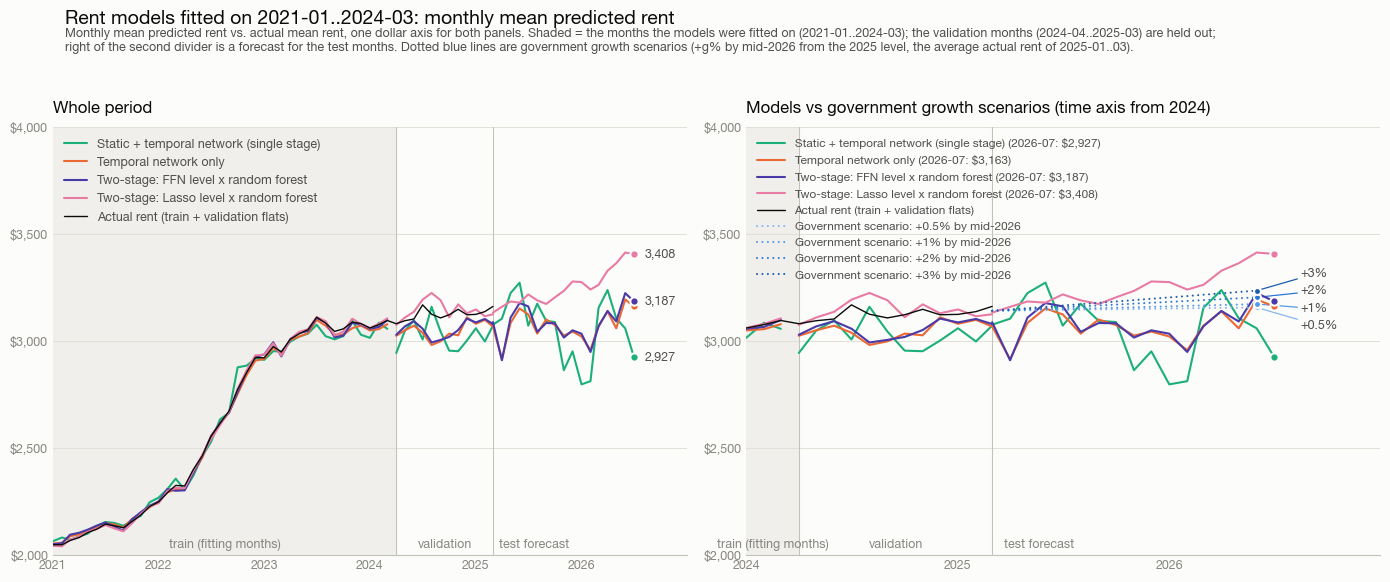

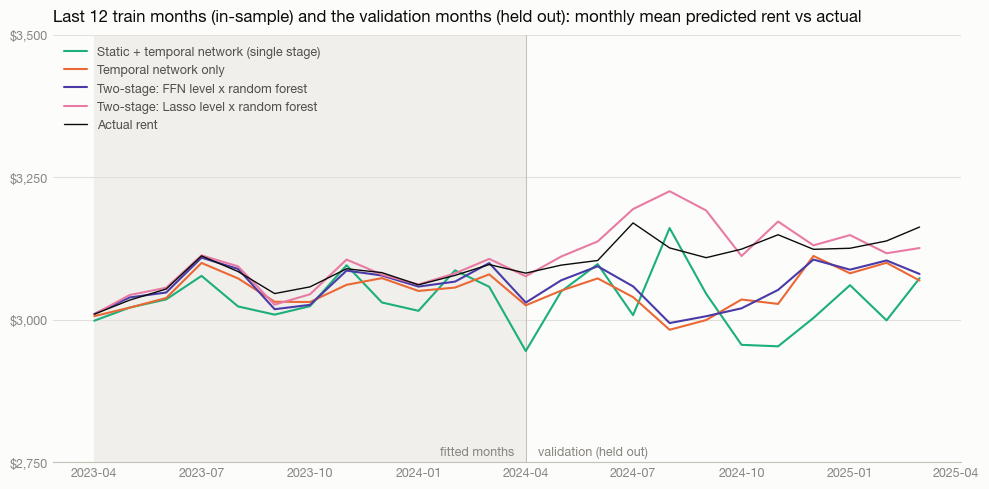

In [7]:
actual_monthly = eu.monthly_mean(fitted_rows['actual'], fitted_rows['month'])
monthly = lambda split, m: eu.monthly_mean(preds[split][m]['prediction'], preds[split][m]['month'])
chart_models = [{'label': label[m], 'fit': monthly('train', m), 'validation': monthly('val', m), 'forecast': monthly('test', m), 'colour': style[m][1]} for m in models]
eu.models_chart(chart_models, actual_monthly, 'Rent models fitted on 2021-01..2024-03: monthly mean predicted rent', out_path=eu.CHART_DIR / 'prediction_chart.png')
plt.show()

first_val = pd.Period(eu.month_label(FIRST_VAL)[0], freq='M')
recent = lambda s: s.loc[first_val - 12:]
eu.validation_chart([{'label': label[m], 'monthly': recent(pd.concat([monthly('train', m), monthly('val', m)])), 'colour': style[m][1]} for m in models],
                    recent(actual_monthly), first_val, 'Last 12 train months (in-sample) and the validation months (held out): monthly mean predicted rent vs actual',
                    out_path=eu.CHART_DIR / 'validation_chart.png')
plt.show()

## 6. Training diagnostics of the neural networks

The epoch losses of the fit (`results/tables/<model>/` of `02_modelling/single_stage_models/neural_network` and `02_modelling/two_stage_models/neural_network`): the RMSE of the train rows and of the validation rows after every epoch. A model whose number of epochs was
chosen on the validation curve has the longer curve it was chosen on (`epoch_losses_selection.csv`), with the epochs used marked. The dotted line is the validation RMSE of the monthly mean rent.

Static + temporal network (single stage): 20 epochs used; validation RMSE 502.5 at the last epoch (best in the curve shown: epoch 17, 492.0)


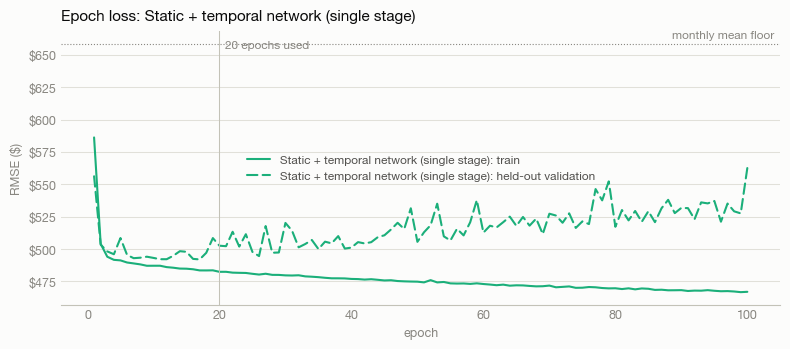

Temporal network only: 100 epochs used; validation RMSE 664.4 at the last epoch (best in the curve shown: epoch 43, 660.7)


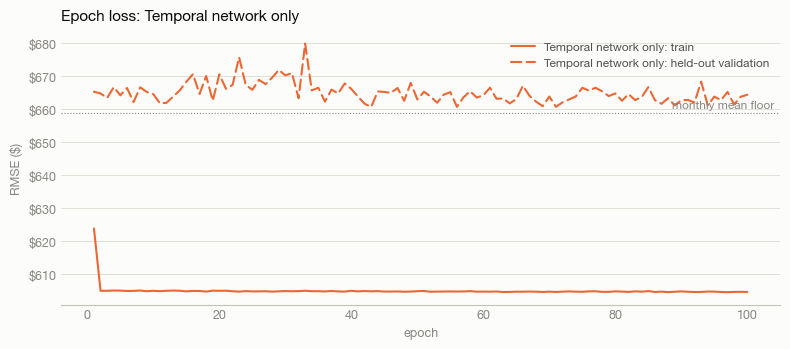

In [8]:
floor = held_out.iloc[len(models)]['RMSE']
find = lambda m, name: next((d / m / name for d in NN_TABLES if (d / m / name).exists()), None)
for m in models:
    used_path = find(m, 'epoch_losses.csv')
    if used_path is None:
        continue
    used = pd.read_csv(used_path).set_index('epoch')
    path = find(m, 'epoch_losses_selection.csv') or used_path
    h = pd.read_csv(path).set_index('epoch')
    eu.loss_chart([{'label': label[m], 'train': h['train_rmse_dollar'], 'valid': h['valid_rmse_dollar'], 'colour': style[m][1]}], f'Epoch loss: {label[m]}',
                  floor=(floor, 'monthly mean floor'), used_epochs=len(used) if len(used) < len(h) else None, out_path=eu.CHART_DIR / f'epoch_loss_{m}.png')
    print(f'{label[m]}: {len(used)} epochs used; validation RMSE {used["valid_rmse_dollar"].iloc[-1]:,.1f} at the last epoch (best in the curve shown: epoch {h["valid_rmse_dollar"].idxmin()}, {h["valid_rmse_dollar"].min():,.1f})')
    plt.show()

## 7. Summary

In [9]:
summary = held_out.iloc[:len(models)].add_prefix('heldout_').join(in_sample.iloc[:len(models)][['RMSE', 'R2']].add_prefix('insample_')).join(growth[['growth at mid-2026', 'avg 2026 growth', 'distance to the 0.5-3% band']])
summary.index.name = 'model'
summary.to_csv(eu.TABLE_DIR / 'model_comparison.csv')
print(summary.round(3).to_string())

                                          heldout_MAE  heldout_RMSE  heldout_R2  heldout_BIAS  insample_RMSE  insample_R2  growth at mid-2026  avg 2026 growth  distance to the 0.5-3% band
model                                                                                                                                                                                      
Static + temporal network (single stage)      383.837       502.544       0.419       -96.569        480.739        0.568               0.002           -0.009                        0.003
Temporal network only                         507.508       664.364      -0.016       -75.642        604.546        0.317               0.036            0.001                        0.006
Two-stage: FFN level x random forest          355.974       475.414       0.480       -66.554        449.510        0.622               0.036            0.001                        0.006
Two-stage: Lasso level x random forest        341.381       